#**1. Observar o Panorama Geral**



Configuração inicial do setup para o notebook.

In [ ]:
import sys
from packaging import version
import sklearn

# garantia da versão do python
assert sys.version_info >= (3, 7)

# garantia da versão do sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

In [ ]:
# Definição de fontes padrão para os gráficos
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

**Dataset:** MNIST, que é um conjunto de 70.000 imagens pequenas de dígitos escritos à mão por estudantes do ensino médio e funcionários do Censo dos EUA.

**Objetivo:** Reconhecer qual dígito foi escrito à mão.

a) Primeiramente, vamos fazer uma clasisficação binária (verificar se o dígito é o número 5 ou não).

**Tipo de Aprendizado:** Aprendizado Supervisionado

**Tipo de Tarefa:** Classificação

**Quantidade de entradas e saídas:** SISO

**Formato de aprendizado:** Aprendizado em lote

**Medida de Desempenho:** Acurácia, Precisão, Recall, Matriz Confusão, Curva ROC


# **2. Obtenção dos Dados**

In [ ]:
# Importar o dataset MINIST
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', as_frame=False)

mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [ ]:
type(mnist.data)

numpy.ndarray

## **2.1. Observação dos Primeiros Dados**

In [ ]:
# os dados em si de entrada e saída são representados por esses atributos
X, y = mnist.data, mnist.target

In [ ]:
# X representa a imagem 28 x 28
print(X)
print(X.shape)

# y representa o label dessa imagem
print(y)
print(y.shape)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(70000, 784)
['5' '0' '4' ... '4' '5' '6']
(70000,)


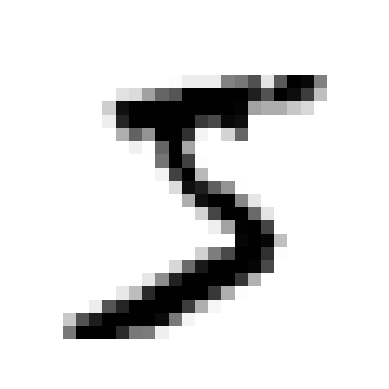

5


In [ ]:
# Representação dos Dados
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

index = 0   # escolha o índice do dataset para mostrar

some_digit = X[index]
plot_digit(some_digit)
plt.show()

# label
print(y[index])

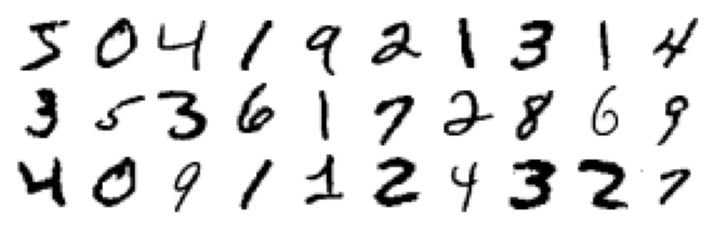

In [ ]:
import math

def plot_digits_grid(X, num_digits=100):
    # Calcula colunas (máximo 10) e linhas necessárias dinamicamente
    cols = min(10, num_digits) # até 10 colunas
    rows = math.ceil(num_digits / cols) # calcula o numero de linhas necessárias

    plt.figure(figsize=(cols * 0.9, rows * 0.9)) # redimensiona o tamanho da figura

    # loop para plotar cada dígito
    for idx, image_data in enumerate(X[:num_digits]):
        plt.subplot(rows, cols, idx + 1)
        plot_digit(image_data)

    plt.subplots_adjust(wspace=0, hspace=0)
    plt.show()

# quantidade de dígitos
num_digits = 30
plot_digits_grid(X, num_digits)

## **2.2. Descrição dos Dados**

In [ ]:
import numpy as np
import pandas as pd

# Converter o array para Pandas
serie = pd.Series(y)

# 2. Usar to_numeric para forçar a conversão. O que não for número vira NaN (Not a Number)
serie_numerica = pd.to_numeric(serie, errors='coerce')

# 3. Agora pode Pandas para checar por nulos
contagem_nulos = serie_numerica.isnull().sum()
print(f"Quantidade de dados nulos (NaN): {contagem_nulos}")

# Mostra quantidade absoluta e relativa lado a lado
distribuicao = pd.DataFrame({
    'Quantidade': serie_numerica.value_counts(dropna=False),
    'Porcentagem': serie_numerica.value_counts(normalize=True, dropna=False).map('{:.2%}'.format)
})
print("\nDistribuição Detalhada das Categorias:")
print(distribuicao)

Quantidade de dados nulos (NaN): 0

Distribuição Detalhada das Categorias:
   Quantidade Porcentagem
1        7877      11.25%
7        7293      10.42%
3        7141      10.20%
2        6990       9.99%
9        6958       9.94%
0        6903       9.86%
6        6876       9.82%
8        6825       9.75%
4        6824       9.75%
5        6313       9.02%


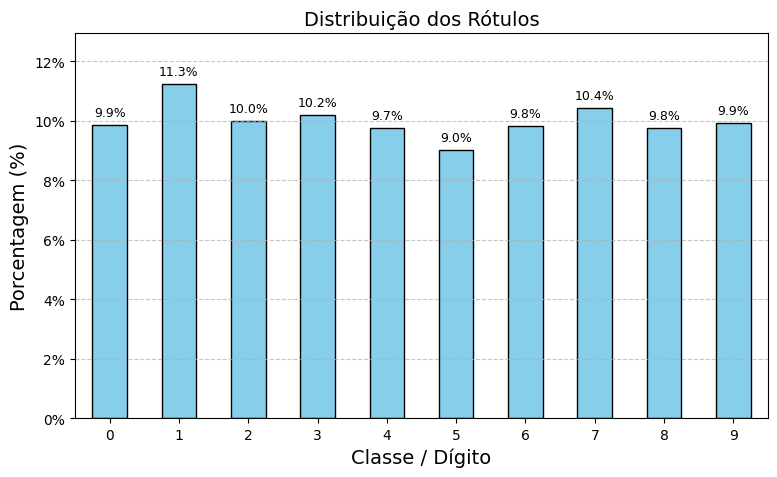

In [ ]:
import matplotlib.ticker as mtick

# 1. Calcula as frequências relativas
proporcoes = serie_numerica.value_counts(normalize=True).sort_index()

plt.figure(figsize=(8, 5))
ax = proporcoes.plot(kind='bar', color='skyblue', edgecolor='black')

# 2. Formata o eixo Y para mostrar % (ex: 10.0%)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# 3. Adiciona o valor em porcentagem no topo de cada barra
for i, valor in enumerate(proporcoes):
    ax.text(
        i,
        valor + 0.002,             # Posição vertical um pouco acima da barra
        f"{valor:.1%}",            # Formatação em porcentagem com 1 casa decimal
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title("Distribuição dos Rótulos")
plt.xlabel("Classe / Dígito")
plt.ylabel("Porcentagem (%)")
plt.xticks(rotation=0)
plt.ylim(0, max(proporcoes) * 1.15)  # Dá um espaço extra no topo para o texto não cortar
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## **2.3. Separação dos Dados de Treino e Teste**

Objetivo primeiramente é uma classificação binária, para identificação de apenas um dígito escolhido.

In [ ]:
# Separação do dígito
digit = '5'
y_binary = (pd.Series(y).astype(str) == digit).astype(int)
y_binary

,0
0,1
1,0
2,0
3,0
4,0
...,...
69995,0
69996,0
69997,0
69998,1


In [ ]:
# Converter o array para Pandas
serie_binaria = pd.Series(y_binary)

# 2. Usar to_numeric para forçar a conversão. O que não for número vira NaN (Not a Number)
serie_numerica_binaria = pd.to_numeric(serie_binaria, errors='coerce')

# 3. Mostra quantidade absoluta e relativa lado a lado
distribuicao_binaria = pd.DataFrame({
    'Quantidade': serie_numerica_binaria.value_counts(dropna=False),
    'Porcentagem': serie_numerica_binaria.value_counts(normalize=True, dropna=False).map('{:.2%}'.format)
})
print("\nDistribuição Detalhada da Classificação Binária:")
print(distribuicao_binaria)


Distribuição Detalhada da Classificação Binária:
   Quantidade Porcentagem
0       63687      90.98%
1        6313       9.02%


In [ ]:
from sklearn.model_selection import train_test_split

# Divisão COM Estratificação
X_train, X_test, y_train, y_test = train_test_split(
   X, y_binary, test_size=0.2, stratify=y_binary, random_state=42)

serie_Strat_Treino = pd.Series(y_train)
serie_Strat_Teste = pd.Series(y_test)

print("Distribuição das categorias no Conjunto de Treino:")
print(serie_Strat_Treino.value_counts(normalize=True).map('{:.2%}'.format))

print("\nDistribuição das categorias no Conjunto de Teste:")
print(serie_Strat_Teste.value_counts(normalize=True).map('{:.2%}'.format))

print("\n--- Usando train_test_split para Divisão ---")
print(f"Formato do conjunto de treino: {X_train.shape}")
print(f"Formato do conjunto de teste: {X_test.shape}")

Distribuição das categorias no Conjunto de Treino:
0    90.98%
1     9.02%
Name: proportion, dtype: object

Distribuição das categorias no Conjunto de Teste:
0    90.98%
1     9.02%
Name: proportion, dtype: object

--- Usando train_test_split para Divisão ---
Formato do conjunto de treino: (56000, 784)
Formato do conjunto de teste: (14000, 784)


# **3. Treinamento do Modelo de Classificação Binária**

##  **3.1 Modelo Gradiente Descendente Estocástico (*Stochastic Gradient Descent*)**

O SGDClassifier do Scikit-Learn é um dos classificadores mais práticos e poderosos. Trata-se de um **classificador linear** que utiliza o algoritmo de Gradiente Descendente Estocástico (*Stochastic Gradient Descent* - SGD) para treinar e ajustar seus parâmetros.

O SGDClassifier é, por natureza, um **classificador estritamente binário**.

É um algoritmo extremamente escalável e rápido para lidar com grandes volumes de dados. Por processar dados de forma **incremental**, esse modelo pode ser continuamente atualizado com novos exemplos de dados sem a necessidade de ser retreinado do zero.

Para cada instância, o modelo calcula uma pontuação (*score*) baseada em uma função de decisão linear (atribuindo pesos para cada característica). Se essa pontuação for maior que um determinado limiar (*threshold*), ele classifica a instância na classe positiva; caso contrário, na classe negativa.

Como o modelo linear depende do gradiente descendente, ele é **altamente sensível à escala das características**. Então, é recomendável fazer a **padronização** dos dados antes de iniciar o treinamento.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Padronizar os pixels do MNIST para melhorar o SGD, já que variam de 0 a 255
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

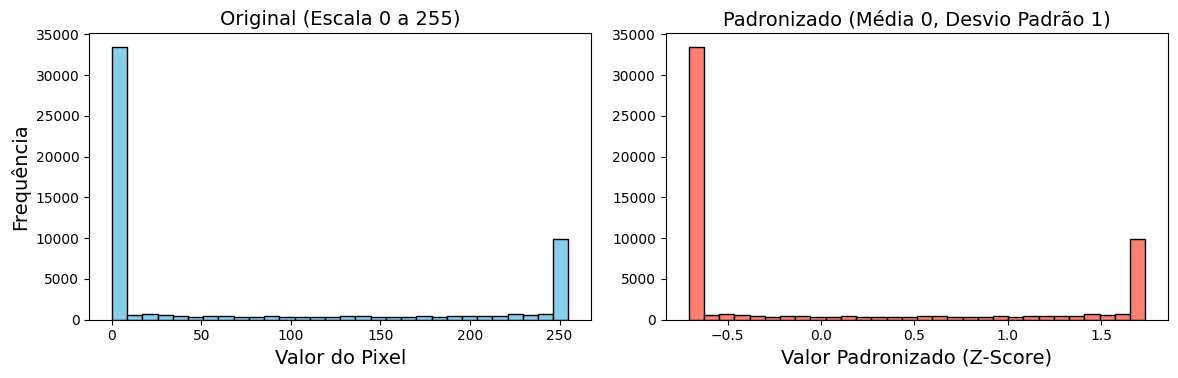

In [ ]:
# Seleciona um pixel específico da imagem que tem 784 pixels
pixel_idx = 400

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico dos dados Originais
axes[0].hist(X_train[:, pixel_idx], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title("Original (Escala 0 a 255)")
axes[0].set_xlabel("Valor do Pixel")
axes[0].set_ylabel("Frequência")

# Gráfico dos dados Padronizados
axes[1].hist(X_train_scaled[:, pixel_idx], bins=30, color='salmon', edgecolor='black')
axes[1].set_title("Padronizado (Média 0, Desvio Padrão 1)")
axes[1].set_xlabel("Valor Padronizado (Z-Score)")

plt.tight_layout()
plt.show()

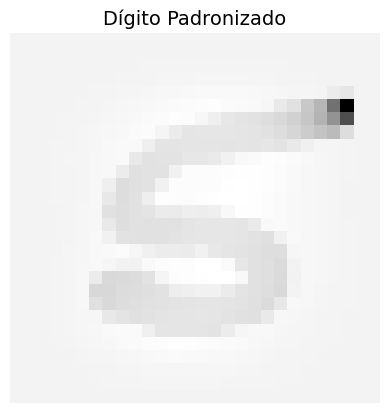

In [ ]:
# Pega a primeira imagem padronizada e ajusta o formato para 28x28
imagem_padronizada = X_train_scaled[16].reshape(28, 28)

plt.imshow(imagem_padronizada, cmap='binary')
plt.title("Dígito Padronizado")
plt.axis('off')
plt.show()

In [ ]:
#  Classificador Binário Descida de Gradiente Estocástico
from sklearn.linear_model import SGDClassifier

# Instanciar com peso balanceado para lidar com o desbalanceamento (9.02% de dígito 5)
sgd_clf = SGDClassifier(class_weight='balanced', random_state=42)
sgd_clf.fit(X_train_scaled, y_train)

SGDClassifier(class_weight='balanced', random_state=42)

In [ ]:
sgd_clf.predict([X_train_scaled[16]])

array([1])

##  **3.2 Modelo Classificador Bobo (*Dummy Classifier*)**

O DummyClassifier é um classificador extremamente simplista que serve como uma linha de base (*baseline*) trivial para avaliar o desempenho de modelos reais de *Machine Learning*.

Esse classificador tem duas configurações:


*   **Classe mais frequente:** O classificador memoriza qual é a classe majoritária no conjunto de treino e prevê apenas ela para toda e qualquer nova amostra. Por exemplo, em um detector do dígito "5", ele simplesmente prevê "não-5" para todas as imagens.

*   E**stratégia Aleatória / Proporcional (padrão):** O classificador faz predições aleatórias, mas gera classes mantendo rigorosamente a mesma proporção de rótulos observada no conjunto de treinamento

O principal valor prático e didático do DummyClassifier é demonstrar a inadequação da acurácia simples como métrica de sucesso em conjuntos de dados desbalanceados. Ou seja, esse algoritmo pode atingir uma alta acurácia, levando ao engano os projetistas.

Qualquer classificador deve **obrigatoriamente superar o desempenho** do dummy por uma margem expressiva.

In [ ]:
# Classificador que sempre prevê a classe majoritária
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy="most_frequent", random_state=42)
dummy_clf.fit(X_train, y_train) # não é necessário padronizar

DummyClassifier(random_state=42, strategy='most_frequent')

In [ ]:
dummy_clf.predict([X_train[16]])

array([0])

##  **3.3 Modelo Floresta Aleatória**

A Floresta Aleatória (Random Forest) é um dos algoritmos de Machine Learning mais poderosos, versáteis e amplamente utilizados na atualidade, servindo tanto para tarefas de regressão quanto de classificação.

Em vez de tentar construir um único modelo, o algoritmo foca em treinar uma grande quantidade de modelos de baixa precisão (árvores de decisão) e depois combinar suas previsões. Isso causa uma redução no problema do *overfitting*.

As florestas aleatórias não exigem escalonamento ou padronização de características (como StandardScaler). Como cada variável é tratada individualmente nas divisões dos nós, a escala física não interfere na performance.

In [ ]:
# Classificador por árvore aleatória

from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(class_weight='balanced',random_state=42)

forest_clf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
forest_clf.predict([X_train[16]])

array([1])

# **4. Avaliação de Perfomance**

Medir o quão bem um modelo de classificação funciona é mais complexo e tem mais nuances do que avaliar um modelo de regressão. Existem muitas medidas de desempenho disponíveis. As mais básicas são:


*   Acurácia
*   Precisão
*   Recall
*   F1-Score




**Acurárcia**

A **acurácia** é a métrica mais intuitiva e direta. Ela indica a proporção de previsões corretas (tanto positivas quanto negativas) em relação ao total de casos avaliados

\begin{equation}
  Acc = \frac{TP + TN}{TP + TN + FP + FN}
\end{equation}

(Onde: TP = Verdadeiros Positivos, TN = Verdadeiros Negativos, FP = Falsos Positivos e FN = Falsos Negativos)

É útil principalmente quando as classes do dataset são bem balanceadas e quando os erros de falsos positivos e falsos negativos têm importância ou custos equivalentes

Contudo, é altamente enganosa em conjuntos de dados desbalanceados. Por exemplo, em um cenário de detecção de uma doença rara ou de cliques em anúncios onde 99% das instâncias são negativas, um modelo "dummy" que simplesmente prevê que ninguém está doente (ou que ninguém clica) obterá 99% de acurácia sem ter aprendido absolutamente nada de útil.

**Precisão**

A **precisão** mede a proporção de previsões de classe positiva que são, de fato, verdadeiramente positivas. Em outras palavras, responde à pergunta: "De todas as instâncias que o modelo classificou como positivas, quantas eram realmente corretas?"

\begin{equation}
  Precision = \frac{TP}{TP + FP}
\end{equation}

Deve ser a métrica prioritária se o objetivo de negócio for limitar ou evitar ao máximo a ocorrência de Falsos Positivos. Priorize a Precisão quando um falso positivo é muito caro.

Exemplos:

*   Filtro de vídeos infantis: Você deseja garantir que o algoritmo exiba apenas vídeos seguros para crianças. É preferível rejeitar alguns vídeos bons desde que nenhum vídeo nocivo passe pelo filtro.

*    Ensaios clínicos farmacêuticos: Como as fases de testes de novos medicamentos são excessivamente caras, uma empresa quer garantir que um composto químico realmente funcione antes de gastar recursos investigando-o.

**Recall**

O **recall** (também conhecido como sensibilidade ou revocação) avalia a capacidade do modelo de encontrar todas as instâncias da classe positiva real. Ele responde à pergunta: "De todos os casos positivos reais existentes, quantos o modelo conseguiu capturar?"

\begin{equation}
  Recall = \frac{TP}{TP + FN}
\end{equation}

Deve ser a métrica prioritária se o objetivo for evitar ao máximo Falsos Negativos. Priorize o Recall quando um falso negativo é muito caro.

Exemplo:

*   Triagem médica (ex: câncer): É muito mais seguro para a vida do paciente receber um alarme falso que exija exames complementares (falso positivo) do que mandar um paciente doente para casa sem tratamento (falso negativo).

*   Sistemas de detecção de fraudes ou roubos: É aceitável gerar alguns alertas falsos para a equipe de segurança revisar, desde que nenhum fraudador ou ladrão real escape sem ser detectado.


**F1-Score**

O **F1-score** (ou estatística F1) combina precisão e recall em um único indicador métrico por meio de uma média harmônica. Ao contrário da média aritmética padrão, a harmônica dá um peso muito maior a valores baixos.

\begin{equation}
  F1_score = 2 \times \frac{Precision \times Recall}{Precision + Recall} = \frac{2TP}{2TP + FP + FN}
\end{equation}

É a métrica mais recomendada quando lidamos com datasets desbalanceados e precisamos de uma métrica de resumo que avalie o equilíbrio real entre precisão e recall.

O classificador só obterá um F1-score alto se tanto a precisão quanto o recall forem simultaneamente altos.

## **4.1 Validação Cruzada**

**SGDClassifier**

In [ ]:
from sklearn.model_selection import cross_validate

# Define a lista de métricas desejadas
metricas = ['accuracy', 'precision', 'recall', 'f1']

# xecuta a validação cruzada calculando todas as métricas juntas
resultados_sgd = cross_validate(
    sgd_clf,
    X_train_scaled,
    y_train,
    cv=3,
    scoring=metricas
)

# Exibe as médias das métricas
print(f"Acurácia:  {resultados_sgd['test_accuracy'].mean():.2%}")
print(f"Precisão:  {resultados_sgd['test_precision'].mean():.2%}")
print(f"Recall:    {resultados_sgd['test_recall'].mean():.2%}")
print(f"F1-Score:  {resultados_sgd['test_f1'].mean():.2%}")

Acurácia:  93.06%
Precisão:  57.56%
Recall:    90.40%
F1-Score:  70.25%


**DummyClassifier**

In [ ]:
# Executa a validação cruzada calculando todas as métricas juntas
resultados_dummy = cross_validate(
    dummy_clf,
    X_train,
    y_train,
    cv=3,
    scoring=metricas
)

# Exibe as médias das métricas
print(f"Acurácia:  {resultados_dummy['test_accuracy'].mean():.2%}")
print(f"Precisão:  {resultados_dummy['test_precision'].mean():.2%}")
print(f"Recall:    {resultados_dummy['test_recall'].mean():.2%}")
print(f"F1-Score:  {resultados_dummy['test_f1'].mean():.2%}")

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Acurácia:  90.98%
Precisão:  0.00%
Recall:    0.00%
F1-Score:  0.00%


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**RandomForest**

In [ ]:
# Executa a validação cruzada calculando todas as métricas juntas
resultados_forest = cross_validate(
    forest_clf,
    X_train,
    y_train,
    cv=3,
    scoring=metricas
)

# Exibe as médias das métricas
print(f"Acurácia:  {resultados_forest['test_accuracy'].mean():.2%}")
print(f"Precisão:  {resultados_forest['test_precision'].mean():.2%}")
print(f"Recall:    {resultados_forest['test_recall'].mean():.2%}")
print(f"F1-Score:  {resultados_forest['test_f1'].mean():.2%}")

Acurácia:  98.71%
Precisão:  99.23%
Recall:    86.32%
F1-Score:  92.32%


**Gráfico dos Resultados de Validação Cruzada**

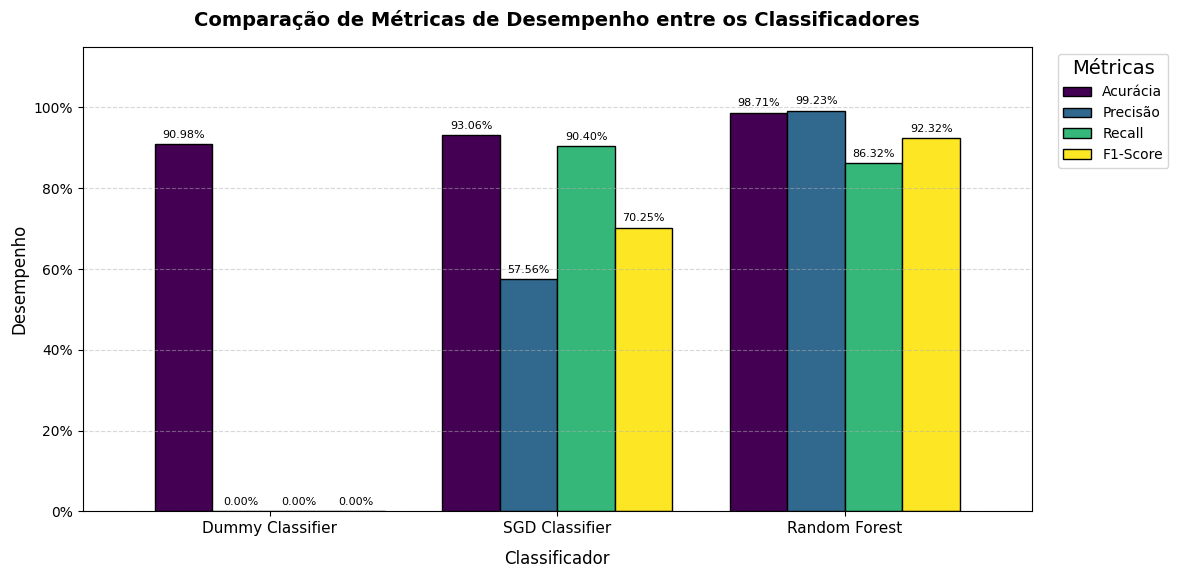

In [ ]:
# estrutura de dados com os resultados de cada cross_validate
dados_comparativos = {
    'Modelo': ['Dummy Classifier', 'SGD Classifier', 'Random Forest'],
    'Acurácia': [
        resultados_dummy['test_accuracy'].mean(),
        resultados_sgd['test_accuracy'].mean(),
        resultados_forest['test_accuracy'].mean()
    ],
    'Precisão': [
        resultados_dummy['test_precision'].mean(),
        resultados_sgd['test_precision'].mean(),
        resultados_forest['test_precision'].mean()
    ],
    'Recall': [
        resultados_dummy['test_recall'].mean(),
        resultados_sgd['test_recall'].mean(),
        resultados_forest['test_recall'].mean()
    ],
    'F1-Score': [
        resultados_dummy['test_f1'].mean(),
        resultados_sgd['test_f1'].mean(),
        resultados_forest['test_f1'].mean()
    ]
}

# Converte para DataFrame
df_comparacao = pd.DataFrame(dados_comparativos)

# Configura o tamanho da figura
fig, ax = plt.subplots(figsize=(12, 6))

# Plota o gráfico de barras diretamente do DataFrame
df_comparacao.set_index('Modelo').plot(
    kind='bar',
    ax=ax,
    width=0.8,
    colormap='viridis',
    edgecolor='black'
)

# Estilização do gráfico
plt.title("Comparação de Métricas de Desempenho entre os Classificadores", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Classificador", fontsize=12, labelpad=10)
plt.ylabel("Desempenho", fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.ylim(0, 1.15)  # Garante espaço no topo para a legenda

# Formata o eixo Y para mostrar porcentagem (ex: 80%)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)

# Adiciona os valores em porcentagem no topo das barras
for container in ax.containers:
    labels = [f"{v * 100:.2f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=8, rotation=0)

plt.tight_layout()
plt.show()

Isso demonstra por que a acurácia por sim só geralmente não é a medida de desempenho preferida para classificadores.

Armadilha: Imagine que o classificador queira diferenciar bolas e laranjas. Nos dados, há 99 laranjas e apenas 1 bola. Se o seu modelo disser "não é uma bola" para TUDO, ele terá uma acurácia de 99%. Acurácia é a medida mais básica, mas pode ser enganosa quando um grupo é muito maior que o outro.



 ### ***Trade-off* da Precisão e Recall**


A ideia mais fundamental é que precisão e recall são inversamente relacionados. Geralmente, ao ajustar um modelo para aumentar sua precisão, o recall tende a diminuir, e vice-versa. Encontrar o equilíbrio certo entre os dois é um dos principais desafios na otimização de um classificador.


**SGDClassifier**

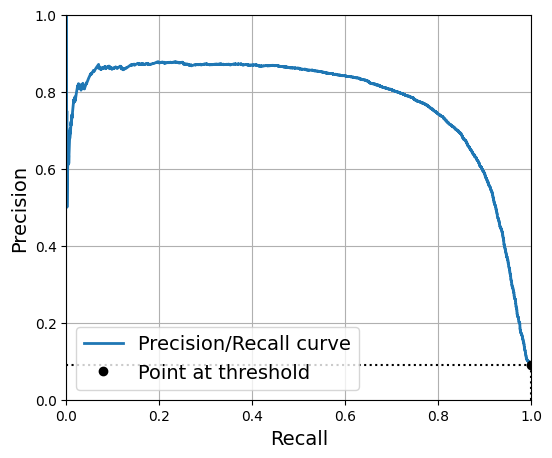

In [ ]:
import matplotlib.patches as patches
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(6, 5))

y_scores = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3,
                             method="decision_function")

precisions, recalls, thresholds = precision_recall_curve(y_train, y_scores)

threshold = 3000
idx = (thresholds >= threshold).argmax()  # first index ≥ threshold

plt.plot(recalls, precisions, linewidth=2, label="Precision/Recall curve")

plt.plot([recalls[idx], recalls[idx]], [0., precisions[idx]], "k:")
plt.plot([0.0, recalls[idx]], [precisions[idx], precisions[idx]], "k:")
plt.plot([recalls[idx]], [precisions[idx]], "ko",
         label="Point at threshold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid()
plt.legend(loc="lower left")

plt.show()

**Random Forest**

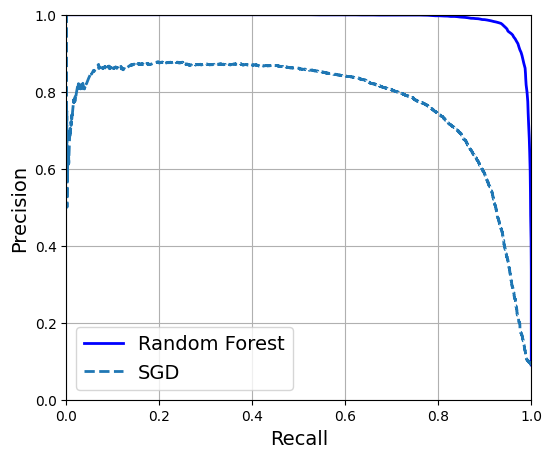

In [ ]:
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train, cv=3,
                                    method="predict_proba")

y_scores_forest = y_probas_forest[:, 1]

precisions_forest, recalls_forest, thresholds_forest = precision_recall_curve(
    y_train, y_scores_forest)

plt.figure(figsize=(6, 5))

plt.plot(recalls_forest, precisions_forest, "b-", linewidth=2,
         label="Random Forest")
plt.plot(recalls, precisions, "--", linewidth=2, label="SGD")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid()
plt.legend(loc="lower left")

plt.show()

## **4.2 Matriz de Confusão**

A Matriz de Confusão é uma tabela que resume o desempenho de um modelo de classificação. Sua principal função é comparar os valores reais das amostras com as previsões feitas pelo algoritmo para revelar exatamente onde e como o modelo está acertando ou falhando.

**SGDClassifier**

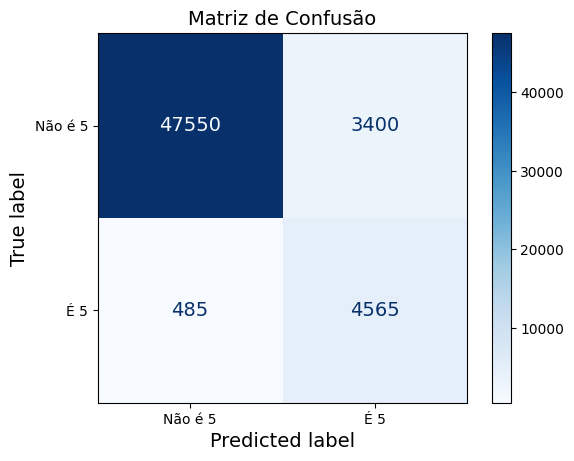

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# gera uma previsão para cada dado do conjunto de treino, mas cada previsão é
# feita por um modelo que nunca viu aquele dado específico durante o treinamento.
y_train_pred_sgd = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3)

cm = confusion_matrix(y_train, y_train_pred_sgd)

# Cria uma visualização a partir da matriz 'cm'
display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                 display_labels=['Não é 5', 'É 5'])

# Plota o gráfico
display.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusão")
plt.show()

**DummyClassifier**

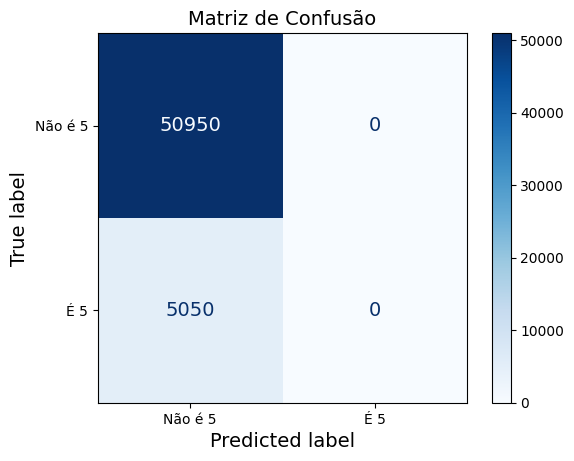

In [ ]:
# gera uma previsão para cada dado do conjunto de treino, mas cada previsão é
# feita por um modelo que nunca viu aquele dado específico durante o treinamento.
y_train_pred_dummy = cross_val_predict(dummy_clf, X_train, y_train, cv=3)

cm = confusion_matrix(y_train, y_train_pred_dummy)

# Cria uma visualização a partir da matriz 'cm'
display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                 display_labels=['Não é 5', 'É 5'])

# Plota o gráfico
display.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusão")
plt.show()

**Random Forest**

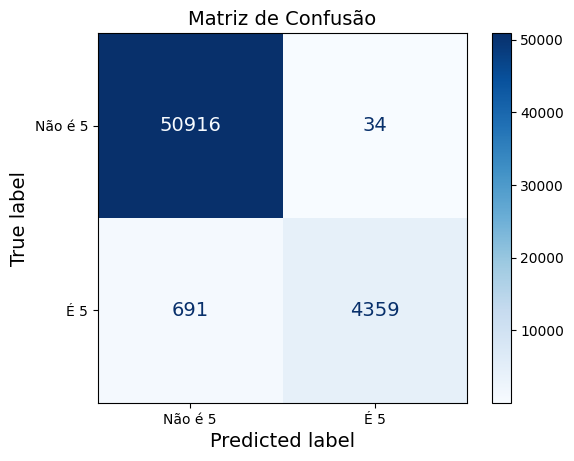

In [ ]:
y_train_pred_forest = cross_val_predict(forest_clf, X_train, y_train, cv=3)

cm = confusion_matrix(y_train, y_train_pred_forest)

# Cria uma visualização a partir da matriz 'cm'
display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                 display_labels=['Não é 5', 'É 5'])

# Plota o gráfico
display.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusão")
plt.show()

# **5. Teste**

## **5.1. SGDClassifier**

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

X_test_scaled = scaler.transform(X_test_array)

print("\n" + "="*40)
print("     TESTE: SGD CLASSIFIER")
print("="*40)

# Predição (Usa dados padronizados X_test_scaled)
y_pred_sgd = sgd_clf.predict(X_test_scaled)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_sgd))

# Resumo
print(f"Acurácia:  {accuracy_score(y_test, y_pred_sgd):.2%}")
print(f"Precisão:  {precision_score(y_test, y_pred_sgd):.2%}")
print(f"Recall:    {recall_score(y_test, y_pred_sgd):.2%}")
print(f"F1-Score:  {f1_score(y_test, y_pred_sgd):.2%}")


     TESTE: SGD CLASSIFIER
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     12737
           1       0.57      0.91      0.70      1263

    accuracy                           0.93     14000
   macro avg       0.78      0.92      0.83     14000
weighted avg       0.95      0.93      0.94     14000

Acurácia:  93.04%
Precisão:  57.16%
Recall:    90.97%
F1-Score:  70.21%


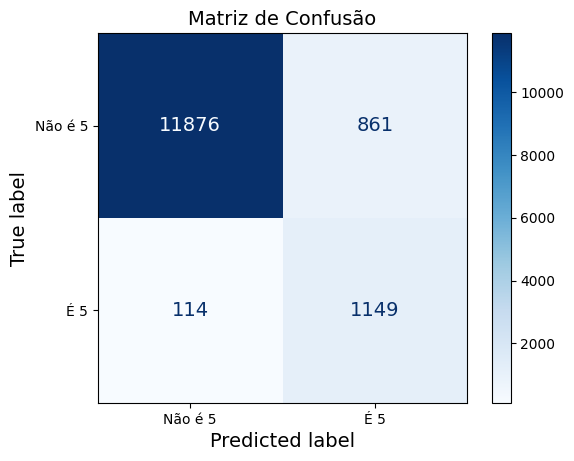

In [ ]:
cm = confusion_matrix(y_test, y_pred_sgd)

# Cria uma visualização a partir da matriz 'cm'
display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                 display_labels=['Não é 5', 'É 5'])

# Plota o gráfico
display.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusão")
plt.show()

## **5.2. DummyClassifier**

In [ ]:
print("="*40)
print("     TESTE: DUMMY CLASSIFIER")
print("="*40)

# Predição
y_pred_dummy = dummy_clf.predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_dummy, zero_division=0))

# Resumo
print(f"Acurácia:  {accuracy_score(y_test, y_pred_dummy):.2%}")
print(f"Precisão:  {precision_score(y_test, y_pred_dummy, zero_division=0):.2%}")
print(f"Recall:    {recall_score(y_test, y_pred_dummy):.2%}")
print(f"F1-Score:  {f1_score(y_test, y_pred_dummy):.2%}")

     TESTE: DUMMY CLASSIFIER
              precision    recall  f1-score   support

           0       0.91      1.00      0.95     12737
           1       0.00      0.00      0.00      1263

    accuracy                           0.91     14000
   macro avg       0.45      0.50      0.48     14000
weighted avg       0.83      0.91      0.87     14000

Acurácia:  90.98%
Precisão:  0.00%
Recall:    0.00%
F1-Score:  0.00%


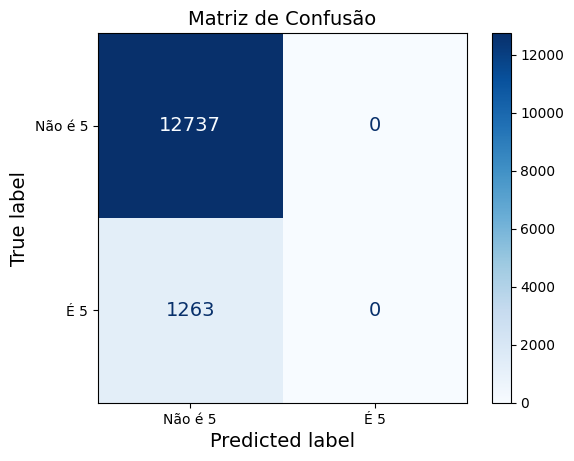

In [ ]:
cm = confusion_matrix(y_test, y_pred_dummy)

# Cria uma visualização a partir da matriz 'cm'
display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                 display_labels=['Não é 5', 'É 5'])

# Plota o gráfico
display.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusão")
plt.show()

## **5.3. Random Forest**

In [ ]:
print("\n" + "="*40)
print("     TESTE: RANDOM FOREST")
print("="*40)

# Predição (Usa X_test_array)
y_pred_forest = forest_clf.predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_forest))

# Resumo
print(f"Acurácia:  {accuracy_score(y_test, y_pred_forest):.2%}")
print(f"Precisão:  {precision_score(y_test, y_pred_forest):.2%}")
print(f"Recall:    {recall_score(y_test, y_pred_forest):.2%}")
print(f"F1-Score:  {f1_score(y_test, y_pred_forest):.2%}")


     TESTE: RANDOM FOREST
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     12737
           1       1.00      0.89      0.94      1263

    accuracy                           0.99     14000
   macro avg       0.99      0.94      0.97     14000
weighted avg       0.99      0.99      0.99     14000

Acurácia:  98.96%
Precisão:  99.56%
Recall:    88.84%
F1-Score:  93.89%


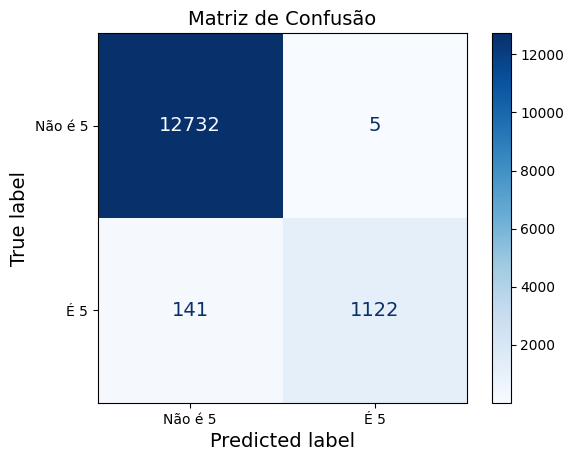

In [ ]:
cm = confusion_matrix(y_test, y_pred_forest)

# Cria uma visualização a partir da matriz 'cm'
display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                 display_labels=['Não é 5', 'É 5'])

# Plota o gráfico
display.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusão")
plt.show()

## **5.4. Resumo do Teste**

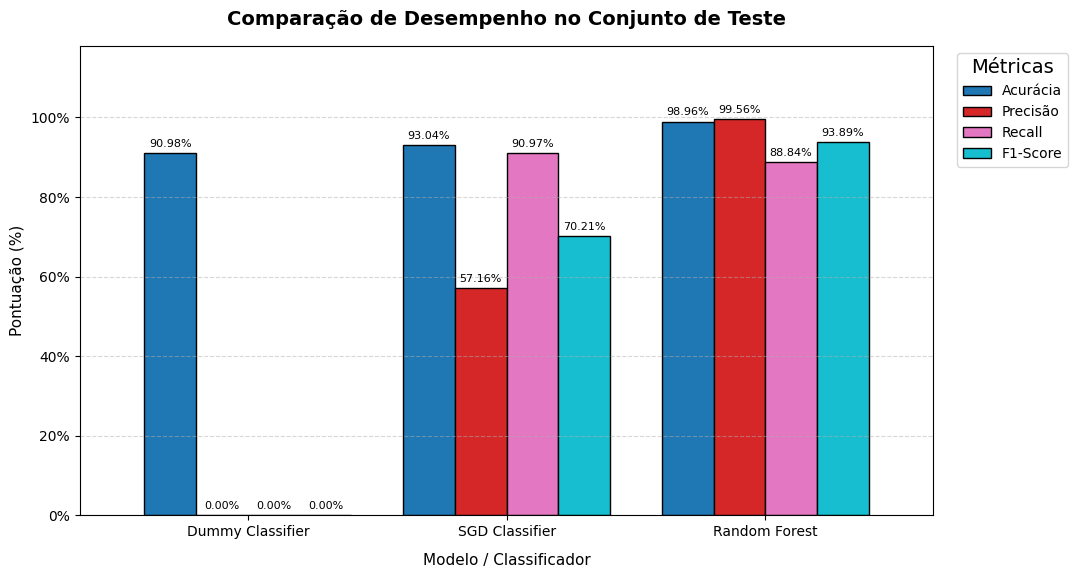

In [ ]:
# Monta a estrutura com os valores numéricos dos testes
dados_grafico = {
    "Modelo": ["Dummy Classifier", "SGD Classifier", "Random Forest"],
    "Acurácia": [
        accuracy_score(y_test, y_pred_dummy),
        accuracy_score(y_test, y_pred_sgd),
        accuracy_score(y_test, y_pred_forest),
    ],
    "Precisão": [
        precision_score(y_test, y_pred_dummy, zero_division=0),
        precision_score(y_test, y_pred_sgd),
        precision_score(y_test, y_pred_forest),
    ],
    "Recall": [
        recall_score(y_test, y_pred_dummy),
        recall_score(y_test, y_pred_sgd),
        recall_score(y_test, y_pred_forest),
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_dummy),
        f1_score(y_test, y_pred_sgd),
        f1_score(y_test, y_pred_forest),
    ],
}

df_plot = pd.DataFrame(dados_grafico)


# 2. Configurações do Gráfico
fig, ax = plt.subplots(figsize=(11, 6))

# Plota o gráfico de barras
df_plot.set_index("Modelo").plot(
    kind="bar", ax=ax, width=0.8, colormap="tab10", edgecolor="black"
)

# Estilização
plt.title(
    "Comparação de Desempenho no Conjunto de Teste",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Modelo / Classificador", fontsize=11, labelpad=10)
plt.ylabel("Pontuação (%)", fontsize=11)
plt.xticks(rotation=0, fontsize=10)
plt.ylim(0, 1.18)  # Espaço para os rótulos no topo das barras
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Formata o eixo Y em Porcentagem
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# Adiciona o valor exato em cima de cada barra
for container in ax.containers:
    labels = [f"{v * 100:.2f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=8, rotation=0)

plt.legend(
    title="Métricas", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10
)
plt.tight_layout()
plt.show()

# **EXERCÍCIO 1**

**Diagnóstico de Câncer e Otimização de Recall**

**Objetivo:** Construir e avaliar modelos de Machine Learning para classificar tumores de mama em Maligno (1) ou Benigno (0).

Treine e avalie os mesmos 3 modelos que usamos.

Avalie a Acurácia, Precisão, Recall e F1-Score.

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

# Imprime o nome de todas as 30 entradas (características)
for i, nome in enumerate(cancer.feature_names):
    print(f"Entrada {i:2d}: {nome}")

Entrada  0: mean radius
Entrada  1: mean texture
Entrada  2: mean perimeter
Entrada  3: mean area
Entrada  4: mean smoothness
Entrada  5: mean compactness
Entrada  6: mean concavity
Entrada  7: mean concave points
Entrada  8: mean symmetry
Entrada  9: mean fractal dimension
Entrada 10: radius error
Entrada 11: texture error
Entrada 12: perimeter error
Entrada 13: area error
Entrada 14: smoothness error
Entrada 15: compactness error
Entrada 16: concavity error
Entrada 17: concave points error
Entrada 18: symmetry error
Entrada 19: fractal dimension error
Entrada 20: worst radius
Entrada 21: worst texture
Entrada 22: worst perimeter
Entrada 23: worst area
Entrada 24: worst smoothness
Entrada 25: worst compactness
Entrada 26: worst concavity
Entrada 27: worst concave points
Entrada 28: worst symmetry
Entrada 29: worst fractal dimension


# **EXERCÍCIO 2**

**Dataset:** Titanic (Titanic - Machine Learning from Disaster), que é um conjunto de dados tabulares contendo informações demográficas e de viagem (como idade, sexo, classe da cabine, tarifa e porto de embarque) de passageiros a bordo do RMS Titanic.

**Objetivo:** Prever se um determinado passageiro sobreviveu ou não ao naufrágio do Titanic.

**Tipo de Aprendizado:** Aprendizado Supervisionado

**Tipo de Tarefa:** Classificação Binária (0 = Não Sobreviveu, 1 = Sobreviveu)

**Quantidade de entradas e saídas:** MISO (Multiple Inputs, Single Output — Múltiplas entradas/atributos tabulares para uma única saída binária)

**Formato de aprendizado:** Aprendizado em lote (Batch Learning)

**Medida de Desempenho:** Acurácia, Precisão, Recall, F1-Score, Matriz de Confusão, Curva ROC e AUC

1. Survival: Sobrevivência (0 = Não, 1 = Sim)

2. pclass: Classe do bilhete (1 = 1ª, 2 = 2ª, 3 = 3ª)
Uma representação do status socioeconômico (SES).

3. sex: Sexo

4. age: Idade em anos. A idade é fracionária se for menor que 1. Se a idade for estimada, ela estará no formato xx,5.

5. sibsp: Número de irmãos / cônjuges a bordo do Titanic

6. parch: Número de pais / filhos a bordo do Titanic

7. ticket: Número do bilhete

8. fare: Tarifa do passageiro

9. cabin: Número da cabine

10. embarked: Porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton)

In [ ]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def load_titanic_data():
    tarball_path = Path("datasets/titanic.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/titanic.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as titanic_tarball:
            titanic_tarball.extractall(path="datasets")

    train_df = pd.read_csv(Path("datasets/titanic") / "train.csv")
    test_df = pd.read_csv(Path("datasets/titanic") / "test.csv")
    return pd.concat([train_df, test_df], ignore_index=True)

#  O objetivo é treinar um classificador que possa prever a coluna Survived com base nas outras colunas.

In [ ]:
data = load_titanic_data()